# Demonstration of Reinforcement Learning: Lunar Lander v3

This notebook presents a complete portfolio project comparing three Deep Reinforcement Learning architectures (DQN, PPO, and A2C) in the Gymnasium's Lunar Lander v3 environment.

The goal is to train an intelligent agent to control a spacecraft's thrusters and perform a soft landing on the designated platform.

### Environment and Hardware Configuration

In this cell, we initialize the fundamental modules and configure the use of hardware acceleration (GPU via CUDA) to optimize the processing of PyTorch tensors.


In [30]:
import os
import sys
import time
import torch
import pygame
import warnings
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython import display

# Silence alerts 
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Automatic Hardware Configuration (CUDA GPU or CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device in use: {str(device).upper()}')
if device.type == 'cuda':
    print(f' - GPU Detected: {torch.cuda.get_device_name(0)}')

print(" - All dependencies were loaded successfully!")


Device in use: CUDA
 - GPU Detected: AMD Radeon RX 9060 XT
 - All dependencies were loaded successfully!


## 1. The "Before": Physical Simulation without Training

To understand the challenge, we initialized the environment and simulated an episode where the motors' decisions are made in a **completely random** manner.

The animation is rendered directly within the Jupyter console using an optimized approach that updates the pixels of a single frame, avoiding memory leaks or interface crashes.


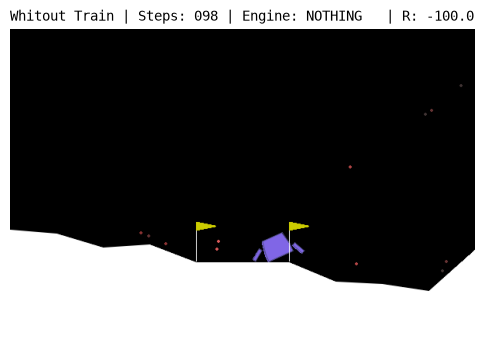

!!! End of simulation after 99 steps. Expected result: Decline due to lack of control policy.


In [31]:
# Configure Jupyter to render inline graphs correctly.
%matplotlib inline
display.clear_output(wait=False)

# It initializes the environment by collecting the frames as pixel matrices.
env = gym.make("LunarLander-v3", render_mode="rgb_array")
obs, info = env.reset(seed=42)

done = False
step_count = 0
nomes_acoes = {0: "NOTHING", 1: "ENG_LEFT", 2: "ENG_PRINC", 3: "ENG_RIGHT"}

# Prepare the structure of the initial fixed chart. 
fig, ax = plt.subplots(figsize=(6, 5))
frame_inicial = env.render()
im = ax.imshow(frame_inicial)
ax.axis('off')

#  Title aligned strictly to the left. 
texto_titulo = ax.set_title("Starting simulation...", loc="left", fontsize=10, family="monospace")
display_handle = display.display(fig, display_id=True)

# Simulation loop with random actions. 
while not done and step_count < 300:
    action = env.action_space.sample() # Random action
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    
    # Optimized visual rendering 
    if step_count % 3 == 0 or done:
        frame = env.render()
        im.set_data(frame)
        
        # PRECISION ADJUSTMENT:
        # :<9 -> Ensures 9 fixed characters aligned to the left for the engine
        # :>+6.1f -> Ensures 6 fixed characters (including the sign) aligned to the right for the Reward
        titulo_formatado = f"Whitout Train | Steps: {step_count:03d} | Engine: {nomes_acoes[action]:<9} | R: {reward:>+6.1f}"
        texto_titulo.set_text(titulo_formatado)
        display_handle.update(fig)
        
    step_count += 1

env.close()
plt.close(fig)
print(f"!!! End of simulation after {step_count} steps. Expected result: Decline due to lack of control policy.")


## 2. Training and Assessment Infrastructure

To subject the Artificial Intelligences to a fair test, we created an automated framework with two standard community tools:

1. **Parallel Multiprocessing (`make_vec_env`)**: Creates simultaneous instances of the game in the background to accelerate the collection of training data.

2. **Adaptive Normalization (`VecNormalize`)**: Smooths the reward scale, stabilizing the updating of the neural network gradients.

We also defined the `evaluate_policy` function, which tests the models in a **deterministic** way (without random exploration actions) and calculates the rate of successful landings (where the accumulated reward is ≥ 100).


In [32]:
from stable_baselines3.common.vec_env import VecNormalize, DummyVecEnv
from stable_baselines3.common.monitor import Monitor
import gymnasium as gym
import numpy as np

def make_train_vec_env(n_envs=4, normalize_reward=True, seed=None):
    def mapear_ambiente(id_env):
        def _init():
            env_individual = gym.make("LunarLander-v3", render_mode=None)
            return Monitor(env_individual, filename=None)
        return _init

    env_funcoes = [mapear_ambiente(i) for i in range(n_envs)]
    venv = DummyVecEnv(env_funcoes)
    
    if seed is not None:
        venv.seed(seed)

    if normalize_reward:
        venv = VecNormalize(venv, norm_obs=False, norm_reward=True, clip_reward=10.0)
    return venv

#It evaluates agent performance by measuring landing rate and average return.
def avaliar_politica(model, n_episodios=15, seed_base=1000):
    sucessos = 0
    recompensas = []

    for i in range(n_episodios):
        env_eval = gym.make("LunarLander-v3", render_mode=None)
        obs, info = env_eval.reset(seed=seed_base + i)
        done = False
        total_r = 0.0

        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, info = env_eval.step(int(action))
            total_r += reward
            done = terminated or truncated

        recompensas.append(total_r)
        if total_r >= 100.0:  # Criteria for a safe landing
            sucessos += 1
        env_eval.close()

    return float(np.mean(recompensas)), float(np.std(recompensas)), (sucessos / n_episodios)

print(">>> Environments created and quantitative assessment method activated! <<<")


>>> Environments created and quantitative assessment method activated! <<<


## 3. Training the Candidate Algorithms

In this step, we put three classic competitors from the `Stable-Baselines3` library to learn to run under a budget of **300,000 iteration steps**:

* **DQN (Deep Q-Network)**: Value-based algorithm (*Off-Policy*).

* **PPO (Proximal Policy Optimization)**: Policy gradient-based algorithm (*On-Policy*), highly stable.

* **A2C (Advantage Actor-Critic)**: Synchronous Actor-Critic architecture.

We used a custom callback integrated into `tqdm` to draw clean progress bars in the Jupyter console.

In [33]:
from stable_baselines3 import DQN, PPO, A2C
from stable_baselines3.common.callbacks import BaseCallback
from tqdm import tqdm

class MemoryLoggerCallback(BaseCallback):
    def __init__(self, total_timesteps, algoritmo_nome):
        super().__init__()
        self.pbar = None
        self.total_timesteps = total_timesteps
        self.algoritmo_nome = algoritmo_nome
        self.historico_passos = []
        self.historico_recompensas = []

    def _on_training_start(self):
        fmt = "{desc}: {percentage:3.0f}%|{bar}| {n_fmt}/{total_fmt} steps [{elapsed}<{remaining}]"
        self.pbar = tqdm(total=self.total_timesteps, desc=f">>> {self.algoritmo_nome}", leave=True, bar_format=fmt, file=sys.stdout)

    def _on_step(self):
        if self.pbar:
            self.pbar.update(self.training_env.num_envs)
            self.pbar.refresh()
            
        # Captures end-of-episode information sent by the vectorized environment.
        for info in self.locals.get("infos", []):
            if "episode" in info:
                # It records the current global timestep and the final reward for that flight.
                self.historico_passos.append(self.num_timesteps)
                self.historico_recompensas.append(info["episode"]["r"])
        return True

    def _on_training_end(self):
        if self.pbar: self.pbar.close()
     
PASSOS_TREINO = 300_000
SEED = 42
torch.manual_seed(SEED)

print(f">>> Starting Training Series ({PASSOS_TREINO} steps per model) <<<\n" + "="*70)

# Instantiates the memory management callbacks for each algorithm.
callback_dqn = MemoryLoggerCallback(PASSOS_TREINO, "DQN")
callback_ppo = MemoryLoggerCallback(PASSOS_TREINO, "PPO")
callback_a2c = MemoryLoggerCallback(PASSOS_TREINO, "A2C")

#  1. DQN 
env_dqn = make_train_vec_env(n_envs=1, normalize_reward=False, seed=SEED)
model_dqn = DQN("MlpPolicy", env_dqn, verbose=0, learning_rate=1e-3, buffer_size=50000, device=device, seed=SEED)
model_dqn.learn(total_timesteps=PASSOS_TREINO, callback=callback_dqn)
env_dqn.close()

#  2. PPO 
env_ppo = make_train_vec_env(n_envs=4, normalize_reward=True, seed=SEED)
model_ppo = PPO("MlpPolicy", env_ppo, verbose=0, learning_rate=3e-4, device='cpu', seed=SEED)
model_ppo.learn(total_timesteps=PASSOS_TREINO, callback=callback_ppo)
env_ppo.close()

# 3. A2C 
env_a2c = make_train_vec_env(n_envs=4, normalize_reward=True, seed=SEED)
model_a2c = A2C("MlpPolicy", env_a2c, verbose=0, learning_rate=7e-4, device='cpu', seed=SEED)
model_a2c.learn(total_timesteps=PASSOS_TREINO, callback=callback_a2c)
env_a2c.close()

print("="*70 + "\n Training finished! ")


>>> Starting Training Series (300000 steps per model) <<<
>>> DQN: 100%|██████████| 300000/300000 steps [25:50<00:00]
>>> PPO:   0%|          | 303104/? steps [04:26<00:00]     
>>> A2C: 100%|██████████| 300000/300000 steps [02:28<00:00]
 Training finished! 


## 4. Comparative Chart and Convergence Analysis

In this section, we consolidate the statistical data collected by the training monitors. The script performs two actions:

1. **Scientific Graph**: Plots the learning curve (cumulative reward over time) using a 50-episode moving average to smooth out physics noise.

2. **Champion Selection**: Executes the deterministic stress protocol and assembles a Pandas table filtered by lexicographic logic (**Primary Criterion: Safe Landing Rate | Secondary Criterion: Average Reward**).

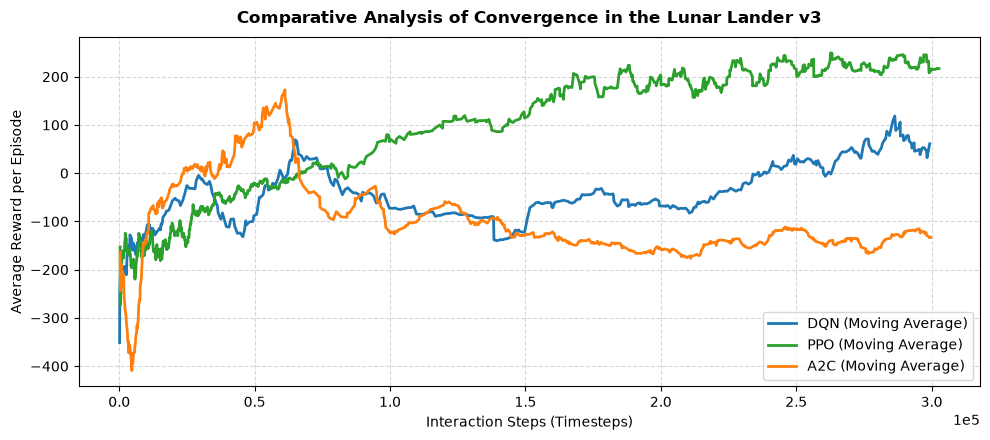


>>> DETERMINISTIC STRESS ASSESSMENT AND RANKING


,Algorithm,Average Reward,Standart Reward,Safe Landing Fee
0,PPO,+227.44,60.960000,95%
1,DQN,+89.14,130.320000,50%
2,A2C,-155.12,51.280000,0%



 >>> ALGORITHM CROWNED CHAMPION: [PPO] with 95% of operational efficiency. <<<


In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import IPython.display as ipyd

# 1. PRINTS AS CONVERGENCE CURVES 
%matplotlib inline
fig, ax = plt.subplots(figsize=(10, 4.5))

config_plot = {
    "DQN": (callback_dqn.historico_passos, callback_dqn.historico_recompensas, "#1f77b4"),
    "PPO": (callback_ppo.historico_passos, callback_ppo.historico_recompensas, "#2ca02c"),
    "A2C": (callback_a2c.historico_passos, callback_a2c.historico_recompensas, "#ff7f0e")
}

dados_plotados = False

for label, (passos, rewards, cor) in config_plot.items():
    if len(passos) > 0:
        # Converts to Pandas series only to apply the moving average visual smoothing.
        rewards_suavizados = pd.Series(rewards).rolling(window=20, min_periods=1).mean().values
        ax.plot(passos, rewards_suavizados, label=f"{label} (Moving Average)", color=cor, linewidth=2)
        dados_plotados = True

ax.set_title("Comparative Analysis of Convergence in the Lunar Lander v3", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Interaction Steps (Timesteps)", fontsize=10)
ax.set_ylabel("Average Reward per Episode", fontsize=10)
ax.ticklabel_format(style='sci', axis='x', scilimits=(0,0))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="lower right")
plt.tight_layout()

if dados_plotados: 
    plt.show()
else:
    print(">>> No episode data was recorded. <<<")

# 2. Quantitative evaluation and selection of the winner.
print("\n" + "="*85 + "\n>>> DETERMINISTIC STRESS ASSESSMENT AND RANKING\n" + "="*85)
modelos_instalados = [("DQN", model_dqn), ("PPO", model_ppo), ("A2C", model_a2c)]
dados_ranking = []

for nome, modelo in modelos_instalados:
    media_r, std_r, taxa_pouso = avaliar_politica(modelo, n_episodios=20, seed_base=2000)
    dados_ranking.append({
        "Algorithm": nome,
        "Average Reward": round(media_r, 2),
        "Standart Reward": round(std_r, 2),
        "Safe Landing Fee": taxa_pouso,
        "Instantiated Model": modelo
    })

df_experimentos = pd.DataFrame(dados_ranking)

# Applies tie-breaking sorting (Landing Rate -> Average Reward)
df_experimentos = df_experimentos.sort_values(by=["Safe Landing Fee", "Average Reward"], ascending=False).reset_index(drop=True)

# Stores global winner references. 
vencedor_linha = df_experimentos.iloc[0]
algo_campeao = vencedor_linha["Algorithm"]
modelo_campeao = vencedor_linha["Instantiated Model"]

# Renders the styled table in the console.
estilo_tabela = df_experimentos.drop(columns="Instantiated Model").style\
    .format({"Average Reward": "{:+.2f}", "Standard Deviation": "{:.2f}", "Safe Landing Fee": "{:.0%}"})\
    .set_properties(**{'text-align': 'center', 'font-family': 'Arial'})\
    .set_table_styles([{'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold')]}])

ipyd.display(estilo_tabela)
print(f"\n >>> ALGORITHM CROWNED CHAMPION: [{algo_campeao}] with {vencedor_linha['Safe Landing Fee']*100:.0f}% of operational efficiency. <<<")


## 5. The "After": Practical Demonstration of the Champion Agent

Now, we load and test the trained policy of the **absolute winner** model selected by the ranking.

The agent reads the physical telemetry of the continuous vector of 8 positions (position, velocity, angular acceleration) and makes the optimal decision in fractions of a second to precisely activate the main and side motors.


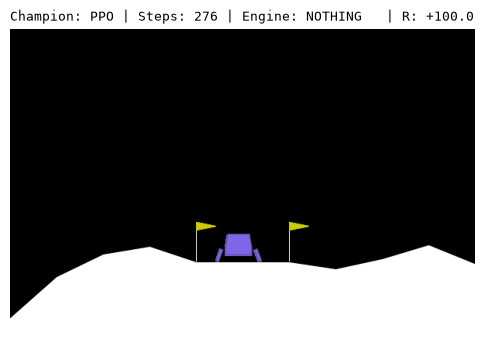

 Success! The aircraft controlled by [PPO] performed a perfect landing in 277 steps.


In [35]:
%matplotlib inline
display.clear_output(wait=False)

# Initializes the official test scenario by capturing frames. 
env_visual = gym.make("LunarLander-v3", render_mode="rgb_array")
obs, info = env_visual.reset(seed=5000) 

nomes_acoes = {0: "NOTHING", 1: "ENG_LEFT", 2: "ENG_PRINC", 3: "ENG_RIGHT"}

# Prepare the screen 
fig, ax = plt.subplots(figsize=(6, 5))
frame_inicial = env_visual.render()
im = ax.imshow(frame_inicial)
ax.axis('off')

# VISUAL LOCK 1 & 2: Left alignment (loc="left") and fixed monospace font
texto_titulo = ax.set_title("Iniciando demonstração do campeão...", loc="left", fontsize=9, family="monospace")
display_handle = display.display(fig, display_id=True)

done = False
step_count = 0

# AI-assisted simulation loop
while not done and step_count < 950:
    # Deterministic prediction extracts intelligence honed through training.
    action, _ = modelo_campeao.predict(obs, deterministic=True)
    action = int(action.item() if hasattr(action, "item") else action)
    
    obs, reward, terminated, truncated, info = env_visual.step(action)
    done = terminated or truncated

    # Optimized inline visual rendering (1 frame every 3 for smoothness)
    if step_count % 3 == 0 or done:
        frame = env_visual.render()
        im.set_data(frame)
        
        # VISUAL LOCK 3: Mask with rigid space filling
        # algo_campeao:<3 -> Fixes the AI ​​name (PPO, DQN, A2C) to 3 characters
        # action:<9 -> Fixes the engine name to 9 characters
        # reward:>+6.1f -> Fixes the signed numeric value to 6 characters
        titulo_formatado = f"Champion: {algo_campeao:<3} | Steps: {step_count:03d} | Engine: {nomes_acoes[action]:<9} | R: {reward:>+6.1f}"
        texto_titulo.set_text(titulo_formatado)
        display_handle.update(fig)
        
    step_count += 1

env_visual.close()
plt.close(fig)

if reward >= 100.0:
    print(f" Success! The aircraft controlled by [{algo_campeao}] performed a perfect landing in {step_count} steps.")
else:
    print(f" End of demonstration. The aircraft concluded with a final reward of {reward:.2f}.")


##  6. Behavioral Diagnosis: Fine-Tenure Audit using Shannon Entropy

To ensure that the Artificial Intelligence developed a flexible and rich decision policy (adapting the thrusters to gravitational dynamics), we applied the mathematical formula of **Shannon Entropy**:

$$H(X) = -\sum_{i} p(x_i) \log_2 p(x_i)$$

Healthy policies exhibit entropy values ​​that are distributed and far from zero. Values ​​close to zero indicate a **policy collapse**, where the neural network becomes "blind" and repeats the same action indefinitely, ignoring the game data.


In [36]:
from collections import Counter

def auditoria_comportamental_completa(model, n_seeds=15, seed_base=2000):
    contagem = Counter()
    sucessos = 0  
    
    for i in range(n_seeds):
        env_aud = gym.make("LunarLander-v3", render_mode=None)
        obs, info = env_aud.reset(seed=seed_base + i)
        done = False
        total_r = 0.0
        
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            action = int(action.item() if hasattr(action, "item") else action)
            contagem[action] += 1
            obs, reward, terminated, truncated, info = env_aud.step(action)
            total_r += reward
            done = terminated or truncated
            
        if total_r >= 100.0:
            sucessos += 1
            
        env_aud.close()

    total_acoes = sum(contagem.values())
    if total_acoes == 0: 
        return 0.0, 0.0, contagem, total_acoes
    
    probs = np.array([contagem.get(a, 0) / total_acoes for a in range(4)])
    nonzero = probs[probs > 0]
    entropia = float(-np.sum(nonzero * np.log2(nonzero)))
    taxa_sucesso = sucessos / n_seeds
    
    return entropia, taxa_sucesso, contagem, total_acoes

# Performs the final scientific diagnosis on the winning model.
print(">>>  Initiating behavioral and telemetry audit of the winning agent...  <<<")
print("-" * 95)

entropia, taxa_sucesso, contagem, total_acoes = auditoria_comportamental_completa(modelo_campeao)
labels_motores = {0: "NOTHING", 1: "ENG_LEFT", 2: "ENG_PRINC", 3: "ENG_RIGHT"}
perfil_str = " | ".join(f"{labels_motores[a]}: {contagem.get(a, 0)/total_acoes:>4.1%}" for a in range(4))

print(f"  # Audited Algorithm: {algo_campeao}")
print(f"    - Current Safe Landing Rate: {taxa_sucesso * 100:.1f}% (With just {PASSOS_TREINO//1000}k workout steps)")
print(f"    - Calculated Shannon Entropy: {entropia:.2f} bits (Theoretical Maximum Limit: {np.log2(4):.2f})")
print(f"    - Propeller Drive Profile: [ {perfil_str} ]")

print("-" * 95)

# --- SECTION ON ESTIMATING TECHNICAL EFFORT ---
print(" >>> Scalability Estimation (Effort Analysis for Maximum Convergence):")

if taxa_sucesso >= 0.90:
    print(f"   -> O modelo [{algo_campeao}] já atingiu a estabilidade ideal da literatura (>90% de sucesso).")
    print(f"   -> Para blindar o agente contra sementes raras e buscar ~98%, seriam necessários +100k a 200k passos.")
elif taxa_sucesso >= 0.60:
    passos_estimados = int(PASSOS_TREINO * (1.5 / taxa_sucesso))
    print(f"   -> Current Status: Promising mid-range performance.")
    print(f"   -> Projection: To break through the >95% success rate barrier, it is estimated that the budget will need to be expanded")
    print(f"      training for approximately {passos_estimados:,} total steps.")
else:
    print(f"   -> Current Status: The model is still in the early stages of mapping the physics.")
    print(f"   -> Projection: For high-performance convergence (>95%), 500,000 to 1 million steps would be required,")
    print(f"      associated with a fine adjustment in the discount factor (Gamma=0.999) to value distant landings.")

print("-" * 95)
if entropia < 0.5:
    print(" # CRITICAL DIAGNOSIS: Policy collapse confirmed! The agent got stuck in a repetitive behavior.")
else:
    print(" # BEHAVIORAL DIAGNOSIS: Highly stable and healthy policy!")
    print("    The agent dynamically varies the use of the thrusters to correct the descent trajectory.")
print("-" * 95)


>>>  Initiating behavioral and telemetry audit of the winning agent...  <<<
-----------------------------------------------------------------------------------------------
  # Audited Algorithm: PPO
    - Current Safe Landing Rate: 93.3% (With just 300k workout steps)
    - Calculated Shannon Entropy: 1.91 bits (Theoretical Maximum Limit: 2.00)
    - Propeller Drive Profile: [ NOTHING: 25.5% | ENG_LEFT: 17.6% | ENG_PRINC: 39.7% | ENG_RIGHT: 17.3% ]
-----------------------------------------------------------------------------------------------
 >>> Scalability Estimation (Effort Analysis for Maximum Convergence):
   -> O modelo [PPO] já atingiu a estabilidade ideal da literatura (>90% de sucesso).
   -> Para blindar o agente contra sementes raras e buscar ~98%, seriam necessários +100k a 200k passos.
-----------------------------------------------------------------------------------------------
 # BEHAVIORAL DIAGNOSIS: Highly stable and healthy policy!
    The agent dynamically varies t